# Planta Física: aprendemos algoritmos genéticos con cuatro decisiones

MA2015.201 · Marzo de 2025 · Una libreta acumulativa.

Construimos un modelo, seguimos una generación y comparamos dos configuraciones pequeñas. Conserva aquí los cálculos, el código y la interpretación de tu equipo.

## Reto: Planta Física - Avance 1: Investigación

**Clave del curso:** MA2015


**Grupo:** 201


**Equipo:** 04


**Integrantes:**

    * Alexandra Natalie Morales Brust   A01661867

    * Axel Rodrigo Vélez Robles         A01668768

    * Leonardo Roldan Perez             A01661235


**Registro de Rotación y Colaboración:**

    * Programación: Alexandra (explicación de la primera parte y comprobó los calculos de Axel)

    * Revisión: Axel (calculo manual y corroboro la explicación de la primera parte)

    * Verificación: Leonardo (verificación final del entregable, confirmando que estuviera completo. Hizo el repositorio.)



## 0. Importamos librerías

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Definimos el problema

Asignamos una fracción de agua tratada a cada edificio para reducir el agua potable. Usamos demandas agregadas reales de marzo de 2025: Aulas 1 = 847 m³, Biblioteca = 462 m³, Cedetec = 284.21 m³ y Aulas 2 = 683 m³. Conservamos ese orden. Los cuatro registros no tienen banderas de imputación, cero ni anomalía.

Adoptamos 1,410 m³ como **capacidad didáctica**, tomada de la calibración docente existente; no es una capacidad confirmada por el socio. También tratamos los límites por edificio como supuestos didácticos.

Codificamos $k=(k_1,k_2,k_3,k_4)$ con enteros: $k_1,k_2,k_4\in\{0,\ldots,8\}$ y $k_3\in\{0,\ldots,6\}$. Interpretamos $x_i=k_i/10$. Por ejemplo, el gen 6 representa 60% de reúso. Hay $9\times9\times7\times9=5103$ combinaciones; exploramos algunas mediante el algoritmo genético.

In [ ]:
BUILDINGS = ("AULAS 1", "BIBLIOTECA", "CEDETEC", "AULAS 2")
DEMAND = np.array([847.0, 462.0, 284.21, 683.0])  # m3, March 2025
LIMITS = np.array([8, 8, 6, 8])  # integer levels; fractions = levels / 10
CAPACITY = 1410.0  # m3; teaching assumption, not confirmed plant capacity

### 1.1 Formulación y Supuesto del modelo
#### A. Decisión física y significado de los genes
El modelo busca optimizar la distribución mensual tanto de agua tratada como de agua potable para los edificios del campus. Primero se define un cromosoma $k = (k_1, k_2, k_3, k_4)$ con cuatro niveles enteros, cada una de estas unidades equivale a diez puntos porcentuales de reúso.
La fracción de reuso es:
* $x_i = \frac{k_i}{10}$ nuestro porcentaje es $100x_i$.

El orden estricto de los edificios es:
1. **$k_1$:** Aulas 1
2. **$k_2$:** Biblioteca
3. **$k_3$:** Cedetec
4. **$k_4$:** Aulas 2

#### B. Datos observados, dominios y capacidades

Tomamos los consumos de **marzo de 2025** con una demanda total $Q = 2276.21\text{ m}^3$. Adoptamos C como el volumen máximo de agua tratada que la planta suministra en el mes. $C = 1410\text{ m}^3$.

| Edificio | Mes | Demanda $D_i$ ($\text{m}^3$) | Dominio de $k_i$ | $x_i = \frac{k_i}{10}$ máximo | Reúso Máximo |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Aulas 1** | Marzo 2025 | 847.00 | $\{0, 1, 2, 3, 4, 5, 6, 7, 8\}$ | 0.8 | 80% |
| **Biblioteca** | Marzo 2025 | 462.00 | $\{0, 1, 2, 3, 4, 5, 6, 7, 8\}$ | 0.8 | 80% |
| **Cedetec**| Marzo 2025 | 284.21 | $\{0, 1, 2, 3, 4, 5, 6\}$ | 0.6 | 60% |
| **Aulas 2** | Marzo 2025 | 683.00 |$\{0,1,2,3,4,5,6,7,8\}$ | 0.8 | 80% |
| **Total Q** | Marzo 2025 | 2276.21 | -------------- | ----| --- |


*Procedencia:* Las demandas son consumos agregados observados en marzo de 2025. Provienen de `assets/kit/datos/consumo_agua_2023_2026.csv` del repositorio técnico MA2015-Planta-Fisica, filtrado a ese mes, tal como indica la celda "Procedencia y entorno" de la base. Los cuatro registros no tienen banderas de imputación, cero ni anomalía. No modificamos estos valores: están fijos en `DEMAND` dentro del código, en el mismo orden de la tabla.

#### C. Objetivo, fórmulas y dirección de aptitud
* **Volúmenes por edificio:** $T_i = D_i \frac{k_i}{10}$  , $P_i = D_i - T_i$
* **Totales del sistema:** $T = \sum T_i$  , $P = Q - T$,   $E = \max(0, T - C)$
* **Objetivo:** Minimizar el agua potable ($P$) y la aptitud $F(k)$, donde un menor valor indica mejor candidato.
$$F(k) = \begin{cases} \frac{P}{Q}, & T \le C \\ 1 + \frac{E}{C}, & T > C \end{cases}$$

  * $T_i = D_i \frac{k_i}{10}$ (agua tratada asignada según el gen).
  * $P_i = D_i - T_i$ (agua potable remanente).

  * $T = \sum T_i$ (total de agua tratada).
  * $P = Q - T$ (total de agua potable).
  * $E = \max(0, T - C)$ (exceso si se supera la capacidad $C = 1410\text{ m}^3$).

  *Un candidato se considera factible si el exceso cumple con la tolerancia $E \le 10^{-8}\text{ m}^3$*.

  **¿Por qué minimizamos agua potable y por qué una aptitud menor es mejor?** Cada metro cúbico que se cubre con agua tratada es uno que no se toma de la red de agua potable. Por eso el objetivo es que $P$ sea lo más pequeño posible sin rebasar lo que la planta puede producir. En la rama factible, $F = P/Q$ es la fracción de la demanda que sigue cubriéndose con agua potable, con valores entre 0 y 1. Un $F$ menor significa más reúso. En la rama infactible, $F = 1 + E/C$ siempre es mayor que 1. Así, cualquier plan que rebase la capacidad queda clasificado detrás de cualquier plan factible, aunque ese plan infactible use menos agua potable. Por eso ordenamos de menor a mayor $F$.

#### D. Naturaleza de los datos: Observados vs. Supuestos Didácticos
* **Datos observados (Demandas $D_i$):**
  * Los consumos reales de agua registrados en el campus durante **marzo de 2025** ($Q = 2276.21\text{ m}^3$). Se utilizan como una base inalterable porque representan la necesidad real de abastecimiento que el sistema debe cubrir mes con mes.
* **Supuestos didácticos (Capacidad $C$ y Máximos de Reúso):**
  * El volumen máximo de agua tratada que la planta suministra en el mes $C = 1410\text{ m}^3$ y los reusos Maximos (80% para Aulas 1 y 2/Biblioteca y 60% para Cedetec) no son mediciones de una infraestructura real ni están confirmados por el socio formador. Son supuestos didácticos: la capacidad proviene de la calibración docente del reto. Sirven para limitar el sistema, generando un conflicto de optimización, obliga a los algoritmos a buscar combinaciones y penalizar los planes que rebasen los límites operativos del campus.
* **Alcance de los supuestos:**
  * El análisis se basa solamente en el mes de marzo de 2025, omitiendo el comportamiento de otros meses, solo ayuda a ver el comportamiento del algoritmo.

## 2. Calculamos agua y aptitud

Definimos agua tratada $T=\sum_iD_i k_i/10$, agua potable $P=\sum_iD_i-T$ y exceso $E=\max(0,T-C)$. Minimizamos $P$ sujeto al dominio y $T\le C$.

Ordenamos candidatos con $F=P/\sum D_i$ si son factibles y $F=1+E/C$ si exceden la capacidad. **Menor aptitud es mejor.** Una solución factible tiene $F\le1$; una infactible tiene $F>1$. Usamos tolerancia numérica de $10^{-8}$ m³.

Antes de ejecutar, calcula a mano $k=(6,6,6,6)$: $T=0.6(2276.21)=1365.726$, $P=910.484$, $E=0$, $F=0.4$. Explica por qué cumple la capacidad y qué unidad tiene cada resultado.

In [ ]:
def evaluate(genes: np.ndarray) -> dict:
    """Return physical totals and fitness (lower is better) for four integer genes."""
    genes = np.asarray(genes)
    if genes.shape != (4,) or not np.issubdtype(genes.dtype, np.integer):
        raise ValueError("Expected four integer genes in building order.")
    if np.any(genes < 0) or np.any(genes > LIMITS):
        raise ValueError("Genes outside the allowed building domains.")
    treated = float(np.sum(DEMAND * genes / 10))
    potable = float(np.sum(DEMAND) - treated)
    excess = max(0.0, treated - CAPACITY)
    feasible = excess <= 1e-8  # numerical tolerance in m3
    fitness = potable / float(np.sum(DEMAND)) if feasible else 1 + excess / CAPACITY
    return dict(treated=treated, potable=potable, excess=excess,
                feasible=feasible, fitness=fitness)

Comprueba tres candidatos: cero reúso, 60% uniforme y máximos del dominio. Distingue cumplir el dominio de cumplir la capacidad. Las claves `treated`, `potable`, `excess`, `feasible` y `fitness` corresponden a $T$, $P$, $E$, factibilidad y $F$.

In [ ]:
cases = [np.zeros(4, dtype=int), np.array([6, 6, 6, 6]), LIMITS.copy()]
for genes in cases:
    print(genes, evaluate(genes))
assert np.isclose(evaluate(cases[1])["potable"], 910.484)
assert evaluate(cases[1])["feasible"]
assert not evaluate(cases[2])["feasible"]

[0 0 0 0] {'treated': 0.0, 'potable': 2276.21, 'excess': 0.0, 'feasible': True, 'fitness': 1.0}
[6 6 6 6] {'treated': 1365.7259999999999, 'potable': 910.4840000000002, 'excess': 0.0, 'feasible': True, 'fitness': 0.4000000000000001}
[8 8 6 8] {'treated': 1764.1260000000002, 'potable': 512.0839999999998, 'excess': 354.1260000000002, 'feasible': False, 'fitness': 1.2511531914893619}


Interpretamos: el plan máximo usa 1764.126 m³ tratados, excede la capacidad en 354.126 m³ y obtiene $F>1$. Aunque reduce más el agua potable, lo descartamos por infactible. Conserva el cálculo manual y la explicación de tu equipo como evidencia de Investigación.

### Cálculo Manual

Calculamos a mano dos candidatos antes de consultar `evaluate()`. Usamos $T_i = D_i \frac{k_i}{10}$ y $P_i = D_i - T_i$ para obtener el agua tratada ($T_i$) y potable ($P_i$) de cada edificio, con $x_i = \frac{k_i}{10}$ como fracción de reúso. Todos los volúmenes están en m³.

#### Candidato 1

Con el candidato $k=(6,6,6,6)$, se usan las fórmulas:

$T_i = D_i \frac{k_i}{10}$ \
$P_i = D_i - T_i$

para calcular $T_i$ (Agua tratada) y $P_i$ (Agua potable) para cada edificio.

- **Aulas 1** \
$T_1 = 847.00\times \frac{6}{10} = 508.2$ m³ \
$P_1 = 847.00 - 508.2 = 338.8$ m³

- **Biblioteca** \
$T_2 = 462.00\times \frac{6}{10} = 277.2$ m³ \
$P_2 = 462.00 - 277.2 = 184.8$ m³

- **Cedetec** \
$T_3 = 284.21\times \frac{6}{10} = 170.526$ m³ \
$P_3 = 284.21 - 170.526 = 113.684$ m³

- **Aulas 2** \
$T_4 = 683.00\times \frac{6}{10} = 409.8$ m³ \
$P_4 = 683.00 - 409.8 = 273.2$ m³


**Tabla por edificio**

| Edificio |  $D_i$ ($\text{m}^3$) | $k_i$ | $x_i$ | $T_i$ ($\text{m}^3$) | $P_i$ ($\text{m}^3$) | $T_i + P_i$ ($\text{m}^3$) |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **Aulas 1** | 847.00 | 6 | 0.6 | 508.200 | 338.800 | 847.00 |
| **Biblioteca** | 462.00 | 6 | 0.6 | 277.200 | 184.800 | 462.00 |
| **Cedetec**| 284.21 | 6 | 0.6 | 170.526 | 113.684 | 284.21 |
| **Aulas 2** | 683.00 | 6 | 0.6 | 409.800 | 273.200 | 683.00 |
| **Total Q** | **2276.21** |  |  | **1365.726** | **910.484** | **2276.21** |

##### Cálculo de totales

- **Agua tratada:** \
$T = T_1+T_2+T_3+T_4 = 508.2 + 277.2 + 170.526 + 409.8 = 1365.726$ m³

- **Agua potable:** \
$P = Q - T = 2276.21 - 1365.726 = 910.484$ m³

- **Comprobación:** \
$T + P = 1365.726 + 910.484 = 2276.21 = Q$


##### Capacidad y Exceso

1365.726 < 1410, por lo que el candidato es factible
$E = max(0 , 1365.726 - 1410) = 0$ m³

##### Aptitud

$F = \frac{910.484}{2276.21} = 0.400000$ (sin unidades)

Este valor significa que el 40% de la demanda total sigue cubriéndose con agua potable


#### Candidato 2 (caso máximo)

Con el candidato $k=(8,8,6,8)$, se usan las fórmulas:

$T_i = D_i \frac{k_i}{10}$ \
$P_i = D_i - T_i$

para calcular $T_i$ (Agua tratada) y $P_i$ (Agua potable) para cada edificio.

- **Aulas 1** \
$T_1 = 847.00\times \frac{8}{10} = 677.6$ m³ \
$P_1 = 847.00 - 677.6 = 169.4$ m³

- **Biblioteca** \
$T_2 = 462.00\times \frac{8}{10} = 369.6$ m³ \
$P_2 = 462.00 - 369.6 = 92.4$ m³

- **Cedetec** \
$T_3 = 284.21\times \frac{6}{10} = 170.526$ m³ \
$P_3 = 284.21 - 170.526 = 113.684$ m³

- **Aulas 2** \
$T_4 = 683.00\times \frac{8}{10} = 546.4$ m³ \
$P_4 = 683.00 - 546.4 = 136.6$ m³


**Tabla por edificio**

| Edificio |  $D_i$ ($\text{m}^3$) | $k_i$ | $x_i$ | $T_i$ ($\text{m}^3$) | $P_i$ ($\text{m}^3$) | $T_i + P_i$ ($\text{m}^3$) |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **Aulas 1** | 847.00 | 8 | 0.8 | 677.600 | 169.400 | 847.00 |
| **Biblioteca** | 462.00 | 8 | 0.8 | 369.600 | 92.400 | 462.00 |
| **Cedetec**| 284.21 | 6 | 0.6 | 170.526 | 113.684 | 284.21 |
| **Aulas 2** | 683.00 | 8 | 0.8 | 546.400 | 136.600 | 683.00 |
| **Total Q** | **2276.21** |  |  | **1764.126** | **512.084** | **2276.21** |

##### Cálculo de totales

- **Agua tratada** \
$T = T_1+T_2+T_3+T_4 = 677.6 + 369.6 + 170.526 + 546.4 = 1764.126$ m³

- **Agua potable** \
$P = Q - T = 2276.21 - 1764.126 = 512.084$ m³

- **Comprobación:** \
$T + P = 1764.126 + 512.084 = 2276.21 = Q$

##### Capacidad y Exceso

1764.126 > 1410, el candidato no es factible
$E = max(0 , 1764.126 - 1410) = 354.126$ m³

##### Aptitud

$F = 1 + \frac{354.126}{1410} = 1.251153$ (sin unidades)

Aunque este plan deja menos agua potable que el Candidato 1 (512.084 m³ frente a 910.484 m³), su aptitud es peor, porque cualquier plan infactible recibe $F > 1$ y queda detrás de todos los factibles.

### Comparación con función evaluate()

In [ ]:
candidato1 = np.array([6, 6, 6, 6], dtype=int)
evaluacion1 = evaluate(candidato1)
print("Candidato 1:", candidato1)
print(evaluacion1)

candidato2 = np.array([8, 8, 6, 8], dtype=int)
evaluacion2 = evaluate(candidato2)
print("Candidato 2:", candidato2)
print(evaluacion2)

Candidato 1: [6 6 6 6]
{'treated': 1365.7259999999999, 'potable': 910.4840000000002, 'excess': 0.0, 'feasible': True, 'fitness': 0.4000000000000001}
Candidato 2: [8 8 6 8]
{'treated': 1764.1260000000002, 'potable': 512.0839999999998, 'excess': 354.1260000000002, 'feasible': False, 'fitness': 1.2511531914893619}


#### Tabla Comparativa: Cálculo Manual vs. 'evaluate()'

**Candidato 1: $k = (6, 6, 6, 6)$**

| Métrica | Cálculo Manual | 'evaluate()' | Diferencia |
| :--- | :--- | :--- | :--- |
| **$T$ (m^3)** | 1365.726000 | 1365.7259999999999 | $< 10^{-12}$ |
| **$P$ (m^3)** | 910.484000 | 910.4840000000002 | $< 10^{-12}$ |
| **$E$ (m^3)** | 0.000000 | 0.000000 | 0.000000 |
| **$F$ (sin unidades)** |  0.400000 | 0.4000000000000001 | $< 10^{-15}$ |
| **Factibilidad** | Factible ($T \le C$) | 'True' | Coinciden |

**Candidato 2 (caso máximo): $k = (8, 8, 6, 8)$**

| Métrica | Cálculo Manual | 'evaluate()' | Diferencia |
| :--- | :--- | :--- | :--- |
| **$T$ (m^3)** | 1764.126000 | 1764.1260000000002 | $< 10^{-12}$ |
| **$P$ (m^3)** | 512.084000 | 512.0839999999998 | $< 10^{-12}$ |
| **$E$ (m^3)** | 354.126000 | 354.1260000000002 | $< 10^{-12}$ |
| **$F$ (sin unidades)** |  1.251153 | 1.2511531914893619 | $< 10^{-12}$ |
| **Factibilidad** | Infactible ($T > C$) | 'False' | Coinciden |


#### Análisis del Caso Máximo ($k = (8, 8, 6, 8)$)

**Por qué los genes son válidos.** Cada gen es un entero dentro de su dominio: $k_1 = 8 \le 8$, $k_2 = 8 \le 8$, $k_3 = 6 \le 6$ y $k_4 = 8 \le 8$. Es decir, cada edificio usa su reúso máximo permitido (80 %, 80 %, 60 % y 80 %). El dominio solo revisa cada gen por separado; no revisa cuánta agua tratada piden los cuatro edificios juntos.

**Por qué aun así rebasa la capacidad.** Al sumar los cuatro edificios, el plan pide $T = 1764.126$ m³ de agua tratada, pero la planta solo puede suministrar $C = 1410$ m³ en el mes. El exceso es $E = 1764.126 - 1410 = 354.126$ m³, cerca de 25 % por encima de la capacidad. Por eso el candidato es infactible, aunque ningún gen esté fuera de su dominio.

**Qué rama de aptitud aplica.** Como $T > C$, se usa la rama penalizada: $F = 1 + \frac{E}{C} = 1 + \frac{354.126}{1410} = 1.251153$. Este valor es mayor que 1, así que el plan queda detrás de cualquier plan factible. Esto pasa aunque deje menos agua potable (512.084 m³) que el Candidato 1 (910.484 m³).

**Qué significa físicamente el exceso.** Los 354.126 m³ de exceso son agua tratada que el plan asigna a los edificios pero que la planta no puede producir en el mes. En la práctica, ese volumen no existiría: los edificios tendrían que cubrirlo con agua potable, así que el plan no se puede ejecutar tal como está escrito.

### Interpretación y Correcciones

**Coincidencias** Los cinco resultados de `evaluate()` coinciden con los resultados del cálculo manual para ambos candidatos. Esto era lo esperado ya que la función aplica las mismas formulas, $T_i = D_i \frac{k_i}{10}$, $T = \sum T_i$, $P = Q - T$, $E = \max(0, T - C)$ y la rama de $F$ que corresponde según la factibilidad. Igualmente se usan los mismos datos (demandas de marzo de 2025 y $C = 1410$ m^3) y el mismo orden de edificios. Con eso comprobamos que se describe el mismo problema.

**Redondeo y punto flotante** Las diferencias que aparecen en las salidas de puntos decimales no son errores del modelo. Sino que vienen de que la computadora representa los decimales en binario lo que le impide guardar exactamente valores cortos o redondeados. Esas diferencias son menores a $10^{-12}$ y no cambian ni la factibilidad ni la rama de aptitud. Por eso tenemos una tolerancia de $10^{-8}$ m^3 para decidir si $E$ es cero. Al presentar los resultados redondeamos a 6 decimales, y los cálculos intermedios sin redondear.


**Corrección realizada** En la primera versión faltaba la tabla comparativa y el análisis del caso máximo. Igualmente ajustamos la aptitud manual del caso máximo de 1.2511 a 1.251153 para que coincida con el redondeo declarado.

### Retroalimentación de Investigación integrada

Atendimos la retroalimentación del 14/10/2026 en esta misma libreta:

- **Capacidad $C$:** la describimos como el volumen máximo de agua tratada que la planta puede suministrar en el mes, supuesto para el ejercicio (sección 1.1, B y D).
- **Procedencia y objetivo:** citamos archivo, mes y fuente de las demandas y explicamos por qué minimizamos el agua potable (sección 1.1, B y C).
- **Comprobación con `evaluate()`:** agregamos la tabla de valor manual, evaluador y diferencia para $T$, $P$, $E$, $F$ y factibilidad, con el redondeo declarado.
- **Caso máximo:** explicamos por qué los genes son válidos, por qué se rebasa $C$, qué rama de aptitud aplica y qué significa el exceso.
- **Código y entorno:** corregimos las etiquetas impresas, usamos los archivos de entorno del kit y ejecutamos desde un kernel reiniciado.

## 3. Generamos una población

Una población es una lista de candidatos. Muestreamos cada gen dentro de su dominio, incluidos los extremos. El muestreo no garantiza capacidad: la función de aptitud ordena también los candidatos infactibles. Fijamos la semilla para reproducir esta demostración.

In [ ]:
def random_individual(rng: np.random.Generator) -> np.ndarray:
    """Sample one valid discrete chromosome; capacity is checked by evaluate."""
    return rng.integers(0, LIMITS + 1)

rng_demo = np.random.default_rng(42)
population_demo = [random_individual(rng_demo) for _ in range(4)]
for genes in population_demo:
    print(genes, evaluate(genes)["fitness"])

[0 6 4 3] 0.7382561362967388
[3 7 0 6] 0.5662526744017468
[1 0 3 8] 0.6852825530157587
[6 6 5 7] 0.38248008751389373


## 4. Seleccionamos padres mediante torneo

Tomamos dos candidatos distintos al azar y elegimos el de menor $F$. Repetimos para elegir otro padre; un mismo individuo puede ganar varios torneos. La selección favorece aptitudes bajas sin ordenar siempre toda la población. Devolvemos una copia para proteger el original.

In [ ]:
def tournament(population: list, rng: np.random.Generator) -> np.ndarray:
    """Return an independent copy of the better of two sampled individuals."""
    indices = rng.choice(len(population), size=2, replace=False)
    winner = min((population[i] for i in indices), key=lambda x: evaluate(x)["fitness"])
    return winner.copy()

parent_a = tournament(population_demo, rng_demo)
parent_b = tournament(population_demo, rng_demo)
print(parent_a, parent_b)

[3 7 0 6] [3 7 0 6]


## 5. Combinamos información con cruza de un punto

Elegimos un corte entre posiciones y tomamos el inicio del primer padre y el final del segundo. Conservamos la posición de cada edificio. Con padres $(6,6,6,6)$ y $(8,2,4,3)$ y corte 2 obtenemos $(6,6,4,3)$. La cruza preserva dominios, pero puede producir exceso de capacidad.

In [ ]:
def crossover(parent_a: np.ndarray, parent_b: np.ndarray,
              rng: np.random.Generator) -> np.ndarray:
    """Create one child using a cut between genes and preserving their positions."""
    cut = int(rng.integers(1, len(LIMITS)))
    return np.concatenate((parent_a[:cut], parent_b[cut:]))

child_demo = crossover(parent_a, parent_b, rng_demo)
print(child_demo, evaluate(child_demo))

[3 7 0 6] {'treated': 987.3, 'potable': 1288.91, 'excess': 0.0, 'feasible': True, 'fitness': 0.5662526744017468}


## 6. Introducimos variación con mutación

Aplicamos la probabilidad a **cada gen**, no al cromosoma completo. Cada gen elegido sube o baja un nivel válido. En cero sólo subimos; en el máximo sólo bajamos. Con $p=0.25$ y cuatro genes, esperamos un gen seleccionado por hijo en promedio, no exactamente uno. La mutación puede mejorar o empeorar la aptitud.

In [ ]:
def mutate(child: np.ndarray, probability: float,
           rng: np.random.Generator) -> np.ndarray:
    """Independently move each selected gene one valid discrete step."""
    if not 0 <= probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    result = child.copy()
    for i, limit in enumerate(LIMITS):
        if rng.random() < probability:
            neighbors = [v for v in (result[i] - 1, result[i] + 1) if 0 <= v <= limit]
            result[i] = rng.choice(neighbors)
    return result

mutated_demo = mutate(child_demo, 0.25, rng_demo)
print(child_demo, mutated_demo, evaluate(mutated_demo))

[3 7 0 6] [3 7 0 7] {'treated': 1055.6, 'potable': 1220.6100000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.5362466556249205}


## 7. Reemplazamos la población y conservamos una élite

Copiamos el mejor individuo sin modificarlo y llenamos las posiciones restantes con hijos. Mantenemos el tamaño de la población. El elitismo evita perder el mejor valor de aptitud; no demuestra que ya encontramos el óptimo. Con una copia independiente, mutar un hijo no modifica al padre ni a la élite.

In [ ]:
def next_generation(population: list, probability: float,
                    rng: np.random.Generator) -> list:
    """Preserve one independent elite and replace all other individuals."""
    elite = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    replacement = [elite]
    while len(replacement) < len(population):
        parent_a = tournament(population, rng)
        parent_b = tournament(population, rng)
        child = crossover(parent_a, parent_b, rng)
        replacement.append(mutate(child, probability, rng))
    return replacement

replacement_demo = next_generation(population_demo, 0.25, rng_demo)
print(min(evaluate(x)["fitness"] for x in population_demo))
print(min(evaluate(x)["fitness"] for x in replacement_demo))

0.38248008751389373
0.38248008751389373


## 8. Cerramos el ciclo

Inicializamos, evaluamos y repetimos selección, cruza, mutación y reemplazo durante un número fijo de generaciones. Registramos el mejor $F$ inicial y después de cada generación. Con 20 generaciones obtenemos 21 valores, incluido el estado inicial. No esperamos una mejora en cada paso.

In [ ]:
def run_ga(population_size: int = 20, generations: int = 20,
           mutation_probability: float = 0.25, seed: int = 42) -> dict:
    """Run a small canonical GA and retain the best fitness at each generation."""
    if not isinstance(population_size, int) or population_size < 2:
        raise ValueError("Population size must be an integer of at least two.")
    if not isinstance(generations, int) or generations < 1:
        raise ValueError("Generations must be a positive integer.")
    if not 0 <= mutation_probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    rng = np.random.default_rng(seed)
    population = [random_individual(rng) for _ in range(population_size)]
    history = [min(evaluate(x)["fitness"] for x in population)]
    for _ in range(generations):
        population = next_generation(population, mutation_probability, rng)
        history.append(min(evaluate(x)["fitness"] for x in population))
    best = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    return dict(genes=best, metrics=evaluate(best), history=np.array(history))

## 9. Ejecuta una configuración base y una variación

Usa 20 individuos, 20 generaciones y semilla 42. En la variación cambia únicamente la probabilidad de mutación de 0.25 a 0.50. Conserva datos, dominios, capacidad y los demás parámetros. Esta comparación describe dos ejecuciones; no demuestra superioridad general de una configuración.

In [ ]:
CONFIG = dict(population_size=20, generations=20, mutation_probability=0.25, seed=42)
baseline = run_ga(**CONFIG)
variant_config = {**CONFIG, "mutation_probability": 0.50}
variant = run_ga(**variant_config)
for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    print(label, "genes =", result["genes"], "fractions =", result["genes"] / 10)
    print(result["metrics"])

p=0.25 genes = [7 4 3 8] fractions = [0.7 0.4 0.3 0.8]
{'treated': 1409.363, 'potable': 866.847, 'excess': 0.0, 'feasible': True, 'fitness': 0.38082909749100474}
p=0.50 genes = [5 7 4 8] fractions = [0.5 0.7 0.4 0.8]
{'treated': 1406.984, 'potable': 869.2260000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.3818742558902738}


## 10. Visualizamos e interpretamos

Leemos el eje horizontal como generación y el vertical como mejor aptitud. Una caída representa mejora; una meseta indica que conservamos el mejor valor. Relacionamos siempre la gráfica con factibilidad y volúmenes. Una gráfica descendente por sí sola no prueba validez física.

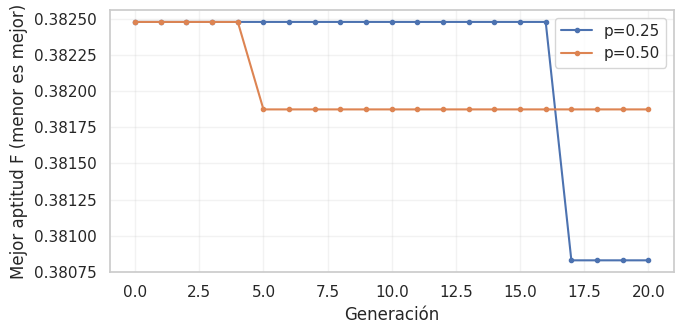

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    ax.plot(range(len(result["history"])), result["history"], marker=".", label=label)
ax.set(xlabel='Generación', ylabel='Mejor aptitud F (menor es mejor)')
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

El parámetro que cambia es la probabilidad de mutación de 0.25 a 0.50.
Los parámetros de población y semilla se quedan igual

Los dos candidatos son factibles y usan casi por completo la capacidad límite

La gráfica de la base tiene un F menor por 0.0010, es igual a 2.379 m³ menos del agua potable. Esto representa un 0.1 % de la demanda total.

Ambas gráficas empiezan con el mismo F igual a 0.3825. La base no presenta ningún cambio hasta la generación 16 y se mejora en la 17, con un valor de 0.3808.

Mientras que, la variación presenta una mejora desde la 4ta generación con un valor de 0.3819, y ya de ahí no cambia.

En el caso de dos ejecuciones no presenta un cambio significante para indicar que la probabilidad de mutación es mejor, con una diferencia de 0.001 en F.

Los genes graficados hacen volúmenes muy similares, con muchas semillas se podría repetir más veces.

## 11. Comprueba reproducción

Repite la configuración base con la misma semilla y comprueba igualdad de genes e historia. Reinicia el kernel y ejecuta de arriba abajo para descartar dependencias de ejecuciones previas. Esta repetición es una comprobación técnica, no una tercera configuración experimental.

In [ ]:
repeated = run_ga(**CONFIG)
np.testing.assert_array_equal(baseline["genes"], repeated["genes"])
np.testing.assert_array_equal(baseline["history"], repeated["history"])
assert np.all(np.diff(baseline["history"]) <= 1e-12)
print('Reproducción y elitismo comprobados.')

Reproducción y elitismo comprobados.


## 12. Conserva evidencia en la misma libreta

- **Investigación (15%)**: formulación y supuestos (60/100); cálculo manual y contraste con el evaluador (40/100).
- **Desarrollo (15%)**: ciclo y operadores funcionales (70/100); una ejecución reproducible e interpretada (30/100).
- **Entrega final (30%)**: explicación de una generación (40/100); dos configuraciones y gráfica (35/100); interpretación física y límites (25/100).

En la entrega final reutiliza las secciones anteriores y añade la explicación de tu equipo. Identifica la base común y cualquier cambio propio. Las funciones adicionales no son necesarias para obtener 100. Conserva los archivos de entorno proporcionados junto a la libreta. La evaluación conjunta del código aporta 10% y el examen individual de artículos 30%. Consulta niveles y fechas en la [guía](guia_reto_planta_fisica.pdf).

 ## Procedencia y entorno

Usamos `assets/kit/datos/consumo_agua_2023_2026.csv` y `assets/kit/parametros_reto.csv` del repositorio técnico MA2015-Planta-Fisica, filtrados a marzo de 2025. La metadata conserva los cuatro registros y los hashes de las fuentes completas. El caso mensual y el código son autónomos.

Con Python 3.12–3.14 y los archivos proporcionados, prepara el entorno con `uv sync --locked` y abre Jupyter con `uv run jupyter lab`. NumPy realiza los cálculos y Matplotlib dibuja la gráfica. Los resultados representan este modelo didáctico, no una recomendación hidráulica o sanitaria validada.

# Reto: Planta Física - Avance 2: Desarrollo

**Clave del curso:** MA2015 · **Grupo:** 201 · **Equipo:** 04

**Integrantes:**

    * Alexandra Natalie Morales Brust   A01661867
    * Axel Rodrigo Vélez Robles         A01668768
    * Leonardo Roldan Perez             A01661235

**Registro de rotación y colaboración (Desarrollo):**

    * Programación: Leonardo. Implementación del código.
    * Revisión: Axel. Chequeo de datos e información general a tomar en cuenta en el entregable.
    * Verificación: Alexandra. Doble chequeo y exportación al repositorio junto con los otros archivos requeridos (formateo general).

En este avance conservamos la libreta acumulativa. La formulación, el cálculo manual y la comparación con `evaluate` de Investigación. Añadimos una variante que modifica **un solo operador: la cruza**. `variant` es la ejecución con pm = 0.50. Para evitar confusiones, en este avance llamamos `res_base` y `res_variante` a los resultados de Desarrollo.



## 13. Desarrollo: variante del algoritmo genético

### 13.1 Versión base y función de cada paso

La versión base es el código de las secciones 3 a 11: las funciones random_individual, tournament, crossover, mutate, next_generation y run_ga (secciones 3 a 8), su ejecución (sección 9), la gráfica (sección 10) y la comprobación de reproducción (sección 11). Usa selección por torneo de dos, cruza de un punto, mutación por gen de ±1 nivel válido, reemplazo generacional y una élite.

| Paso del ciclo | Función | Qué hace | ¿Cambia en la variante? |
| :--- | :--- | :--- | :--- |
| Inicialización | `random_individual` | Muestrea cada gen dentro de su dominio con `default_rng(42)`. | No |
| Evaluación | `evaluate` | Calcula $T$, $P$, $E$, factibilidad y $F$ (menor es mejor). | No |
| Selección | `tournament` | Toma dos candidatos distintos y devuelve una copia del de menor $F$. | No |
| **Cruza** | `crossover` (base) / `crossover_uniform` (variante) | Combina dos padres para formar un hijo. | **Sí** |
| Mutación | `mutate` | Con probabilidad pm por gen, sube o baja un nivel válido. | No |
| Reemplazo y élite | `next_generation` / `next_generation_variant` | Copia el mejor individuo y llena el resto con hijos, de modo que la población se mantiene en 20. | No (solo llama a la cruza elegida) |
| Ciclo | `run_ga` / `run_ga_variant` | Repite 20 generaciones y registra la mejor $F$ de cada una. | No |

### 13.2 Limitación, hipótesis y cambio

**Limitación que atendemos.** Con cuatro genes, la cruza de un punto solo puede cortar en tres lugares (1|3, 2|2 y 3|1). Para un par de padres distintos produce como máximo **3 hijos distintos**. Además, deja siempre juntos a los genes vecinos (Aulas 1 con Biblioteca, Biblioteca con Cedetec, Cedetec con Aulas 2). Ese orden es una convención de la tabla de datos, no una relación física entre edificios. Por ejemplo, con los padres $(6,6,6,6)$ y $(8,2,4,3)$ la cruza de un punto no puede producir $(8,6,4,6)$, que toma Aulas 1 y Cedetec de un padre y Biblioteca y Aulas 2 del otro.

Esto importa porque el problema se parece a una mochila. Cada nivel de reúso aporta un volumen distinto de agua tratada (Aulas 1: 84.7 m³; Biblioteca: 46.2 m³; Cedetec: 28.421 m³; Aulas 2: 68.3 m³). Los mejores planes factibles usan casi toda la capacidad de 1410 m³ sin rebasarla. Para acercarse a ese límite hay que combinar niveles de edificios que no son vecinos en el cromosoma.

**Cambio propuesto.** Sustituimos la cruza de un punto por una **cruza uniforme**. Cada gen del hijo se hereda del padre A o del padre B según una máscara. Elegimos la máscara entre las 14 no triviales (se excluyen "todo A" y "todo B", que copiarían a un padre sin recombinar).

**Hipótesis.** Con la cruza uniforme, el operador explora 14 recombinaciones por pareja en lugar de 3 y puede unir genes no contiguos de buenos padres. Esperamos, con las mismas condiciones, encontrar una asignación factible con menor agua potable $P$ (menor $F$) que la base. Con una sola semilla, interpretaremos el resultado así: si $F_{\text{variante}} < F_{\text{base}}$, apoya la hipótesis; si son iguales, no permite distinguir las versiones; si $F_{\text{variante}} > F_{\text{base}}$, la contradice. En los tres casos se comparan solo candidatos factibles.

In [ ]:
print("Python:", platform.python_version())
print("NumPy:", np.__version__, "| pandas:", pd.__version__, "| Matplotlib:", matplotlib.__version__)

SEED = 42
CONFIG_DES = dict(population_size=20, generations=20, mutation_probability=0.25, seed=SEED)

condiciones = pd.DataFrame({
    "Condición": ["Población / generaciones", "Semilla", "Mutación", "Población inicial",
                  "Selección", "Cruza", "Mutación (operador)", "Reemplazo y elitismo", "Problema y evaluador"],
    "Base": ["20 / 20", "42", "pm = 0.25 por gen", "random_individual, default_rng(42)",
             "Torneo de dos", "Un punto", "±1 nivel válido por gen", "Generacional, 1 élite", "evaluate (sin cambios)"],
    "Variante": ["20 / 20", "42", "pm = 0.25 por gen", "random_individual, default_rng(42)",
                 "Torneo de dos", "UNIFORME (cambio)", "±1 nivel válido por gen", "Generacional, 1 élite", "evaluate (sin cambios)"],
})
print(condiciones.to_string(index=False))

Python: 3.13.16
NumPy: 2.1.3 | pandas: 2.2.3 | Matplotlib: 3.10.0
               Condición                               Base                           Variante
Población / generaciones                            20 / 20                            20 / 20
                 Semilla                                 42                                 42
                Mutación                  pm = 0.25 por gen                  pm = 0.25 por gen
       Población inicial random_individual, default_rng(42) random_individual, default_rng(42)
               Selección                      Torneo de dos                      Torneo de dos
                   Cruza                           Un punto                  UNIFORME (cambio)
     Mutación (operador)            ±1 nivel válido por gen            ±1 nivel válido por gen
    Reemplazo y elitismo              Generacional, 1 élite              Generacional, 1 élite
    Problema y evaluador             evaluate (sin cambios)             evaluat

### 13.3 Operador modificado: cruza uniforme

`crossover_uniform` sortea un entero `code` entre 1 y 14. Sus cuatro bits forman la máscara: un bit en 1 significa que ese gen viene del padre A, y en 0, del padre B. Como cada gen proviene de un padre y conserva su posición, el hijo respeta los dominios de cada edificio. Los padres no se modifican, porque `np.where` crea un arreglo nuevo. La función `hijos_alcanzables` enumera todos los hijos que cada operador puede producir para un par de padres.

In [ ]:
N_GENES = len(LIMITS)

def crossover_uniform(parent_a: np.ndarray, parent_b: np.ndarray,
                      rng: np.random.Generator) -> np.ndarray:
    """Create one child taking each gene from parent A or parent B (uniform crossover)."""
    code = int(rng.integers(1, 2 ** N_GENES - 1))              # máscara no trivial: 1..14
    from_a = ((code >> np.arange(N_GENES)) & 1).astype(bool)   # bit i = 1 -> gen i viene de A
    return np.where(from_a, parent_a, parent_b)

def hijos_alcanzables(parent_a, parent_b, operador):
    hijos = set()
    if operador == "un_punto":
        for cut in range(1, N_GENES):
            hijos.add(tuple(int(v) for v in np.concatenate((parent_a[:cut], parent_b[cut:]))))
    else:
        for code in range(1, 2 ** N_GENES - 1):
            from_a = ((code >> np.arange(N_GENES)) & 1).astype(bool)
            hijos.add(tuple(int(v) for v in np.where(from_a, parent_a, parent_b)))
    return hijos

pa = np.array([6, 6, 6, 6])
pb = np.array([8, 2, 4, 3])
un_punto = hijos_alcanzables(pa, pb, "un_punto")
uniforme = hijos_alcanzables(pa, pb, "uniforme")
print("Hijos alcanzables con cruza de un punto:", len(un_punto), sorted(un_punto))
print("Hijos alcanzables con cruza uniforme   :", len(uniforme))
print("Solo alcanzables con la uniforme       :", len(uniforme - un_punto))
print("¿(8, 6, 4, 6) con un punto? ", (8, 6, 4, 6) in un_punto, "| ¿con uniforme? ", (8, 6, 4, 6) in uniforme)

rng_demo_u = np.random.default_rng(7)
hijo_u = crossover_uniform(pa, pb, rng_demo_u)
print("Hijo uniforme de demostración:", hijo_u, evaluate(hijo_u))

Hijos alcanzables con cruza de un punto: 3 [(6, 2, 4, 3), (6, 6, 4, 3), (6, 6, 6, 3)]
Hijos alcanzables con cruza uniforme   : 14
Solo alcanzables con la uniforme       : 11
¿(8, 6, 4, 6) con un punto?  False | ¿con uniforme?  True
Hijo uniforme de demostración: [8 6 6 6] {'treated': 1535.126, 'potable': 741.0840000000001, 'excess': 125.12599999999998, 'feasible': False, 'fitness': 1.0887418439716312}


### 13.4 Ciclo completo de la variante

next_generation_variant y run_ga_variant son copias del código base con un cambio de comportamiento y un parámetro añadido. El cambio es la cruza: en lugar de crossover (un punto), la línea child = crossover_fn(...) usa por defecto crossover_uniform. El parámetro añadido es crossover_fn, que solo selecciona qué cruza se aplica. Además, run_ga_variant devuelve datos extra (population, initial_population, sizes) para las verificaciones; no alteran el algoritmo. La base sigue intacta y se ejecuta con `run_ga`. El parámetro `crossover_fn` solo selecciona la cruza y permite un **control de equivalencia**: si se le pasa la cruza de la base, el motor de la variante debe reproducir exactamente la base. Eso demuestra que lo único que cambia entre ambas versiones es el operador de cruza.

`run_ga_variant` conserva la población inicial y los tamaños por generación para poder verificar población constante.

In [ ]:
def next_generation_variant(population: list, probability: float,
                            rng: np.random.Generator,
                            crossover_fn=crossover_uniform) -> list:
# Same as next_generation (base); the crossover operator is now selectable via crossover_fn.
    elite = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    replacement = [elite]
    while len(replacement) < len(population):
        parent_a = tournament(population, rng)
        parent_b = tournament(population, rng)
        child = crossover_fn(parent_a, parent_b, rng)   # <-- LÍNEA MODIFICADA: Cruza seleccionable (base: crossover(...))
        replacement.append(mutate(child, probability, rng))
    return replacement

def run_ga_variant(population_size: int = 20, generations: int = 20,
                   mutation_probability: float = 0.25, seed: int = 42,
                   crossover_fn=crossover_uniform) -> dict:
    """Same cycle as run_ga (base) but with next_generation_variant."""
    if not isinstance(population_size, int) or population_size < 2:
        raise ValueError("Population size must be an integer of at least two.")
    if not isinstance(generations, int) or generations < 1:
        raise ValueError("Generations must be a positive integer.")
    if not 0 <= mutation_probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    rng = np.random.default_rng(seed)
    population = [random_individual(rng) for _ in range(population_size)]
    initial_population = [x.copy() for x in population]
    history = [min(evaluate(x)["fitness"] for x in population)]
    sizes = [len(population)]
    for _ in range(generations):
        population = next_generation_variant(population, mutation_probability, rng, crossover_fn)
        history.append(min(evaluate(x)["fitness"] for x in population))
        sizes.append(len(population))
    best = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    return dict(genes=best, metrics=evaluate(best), history=np.array(history),
                population=population, initial_population=initial_population,
                sizes=np.array(sizes))

### 13.5 Verificaciones antes de comparar

Comprobamos cinco cosas: (1) el control de equivalencia; (2) que ambas versiones parten de la misma población inicial; (3) población constante y genes dentro de dominio; (4) que la cruza uniforme produce hijos válidos, hereda cada gen de un padre y no modifica a los padres; (5) que la élite se copia intacta y la mejor aptitud nunca empeora.

In [ ]:
def dominio_valido(genes) -> bool:
    genes = np.asarray(genes)
    return bool(genes.shape == (N_GENES,) and np.issubdtype(genes.dtype, np.integer)
                and np.all(genes >= 0) and np.all(genes <= LIMITS))

# 1) Control de equivalencia
ref_base = run_ga(**CONFIG_DES)
ctrl = run_ga_variant(**CONFIG_DES, crossover_fn=crossover)
np.testing.assert_array_equal(ctrl["genes"], ref_base["genes"])
np.testing.assert_array_equal(ctrl["history"], ref_base["history"])
print("1) Control: el motor de la variante con la cruza base reproduce la base.")

# 2) Misma población inicial
rng_chk = np.random.default_rng(SEED)
pob_ini = [random_individual(rng_chk) for _ in range(CONFIG_DES["population_size"])]
prueba = run_ga_variant(**CONFIG_DES)
assert all(np.array_equal(a, b) for a, b in zip(pob_ini, prueba["initial_population"]))
print("2) La población inicial (semilla 42) es la misma para ambas versiones.")

# 3) Tamaño de población y dominios
assert np.all(prueba["sizes"] == CONFIG_DES["population_size"])
assert all(dominio_valido(x) for x in prueba["population"])
print("3) Población constante (20) en las 21 mediciones y todos los genes dentro de dominio.")

# 4) Cruza uniforme: hijos válidos, cada gen viene de un padre, padres intactos
rng_t = np.random.default_rng(0)
for _ in range(1000):
    a, b = random_individual(rng_t), random_individual(rng_t)
    a0, b0 = a.copy(), b.copy()
    h = crossover_uniform(a, b, rng_t)
    assert dominio_valido(h) and np.all((h == a0) | (h == b0))
    assert np.array_equal(a, a0) and np.array_equal(b, b0)
print("4) crossover_uniform: 1000 hijos válidos, cada gen viene de un padre, padres intactos.")

# 5) Élite protegida
rng_e = np.random.default_rng(1)
for _ in range(200):
    pop = [random_individual(rng_e) for _ in range(20)]
    mejor = min(evaluate(x)["fitness"] for x in pop)
    elite_antes = min(pop, key=lambda x: evaluate(x)["fitness"]).copy()
    nueva = next_generation_variant(pop, 0.25, rng_e)
    assert len(nueva) == 20 and np.array_equal(nueva[0], elite_antes)
    assert min(evaluate(x)["fitness"] for x in nueva) <= mejor + 1e-12
assert np.all(np.diff(prueba["history"]) <= 1e-12)
print("5) Élite protegida: se copia intacta y la mejor aptitud nunca empeora.")

1) Control: el motor de la variante con la cruza base reproduce la base.
2) La población inicial (semilla 42) es la misma para ambas versiones.
3) Población constante (20) en las 21 mediciones y todos los genes dentro de dominio.
4) crossover_uniform: 1000 hijos válidos, cada gen viene de un padre, padres intactos.
5) Élite protegida: se copia intacta y la mejor aptitud nunca empeora.


### 13.6 Ejecución controlada: base frente a variante

Ejecutamos cada versión **desde el inicio** con `seed = 42`, 20 individuos, 20 generaciones y pm = 0.25 por gen. Cada llamada crea su propio generador `default_rng(42)`, así que ninguna ejecución arrastra el estado aleatorio de la otra. Repetimos ambas ejecuciones y verificamos que producen genes e historia idénticos. El mismo evaluador `evaluate` calcula todas las medidas.

In [ ]:
res_base = run_ga(**CONFIG_DES)
res_variante = run_ga_variant(**CONFIG_DES)

# Repetición desde el inicio
res_base_2 = run_ga(**CONFIG_DES)
res_variante_2 = run_ga_variant(**CONFIG_DES)
np.testing.assert_array_equal(res_base["genes"], res_base_2["genes"])
np.testing.assert_array_equal(res_base["history"], res_base_2["history"])
np.testing.assert_array_equal(res_variante["genes"], res_variante_2["genes"])
np.testing.assert_array_equal(res_variante["history"], res_variante_2["history"])
print("Repetición verificada: ambas versiones reproducen genes e historia con semilla 42.\n")

for etiqueta, r in [("BASE (cruza de un punto)", res_base), ("VARIANTE (cruza uniforme)", res_variante)]:
    print(etiqueta, "| genes =", r["genes"], "| fracciones =", r["genes"] / 10)
    print(evaluate(r["genes"]))

Repetición verificada: ambas versiones reproducen genes e historia con semilla 42.

BASE (cruza de un punto) | genes = [7 4 3 8] | fracciones = [0.7 0.4 0.3 0.8]
{'treated': 1409.363, 'potable': 866.847, 'excess': 0.0, 'feasible': True, 'fitness': 0.38082909749100474}
VARIANTE (cruza uniforme) | genes = [8 6 4 5] | fracciones = [0.8 0.6 0.4 0.5]
{'treated': 1409.984, 'potable': 866.2260000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.38055627556332683}


In [ ]:
def fila(genes):
    m = evaluate(genes)
    return dict(genes=tuple(int(v) for v in genes), **m)

b, v = fila(res_base["genes"]), fila(res_variante["genes"])
Q = float(DEMAND.sum())

tabla = pd.DataFrame({
    "Medida": ["Cromosoma final (k1, k2, k3, k4)", "Agua tratada T (m3)", "Agua potable P (m3)",
               "Aptitud F", "Exceso E (m3)", "Genes dentro de dominio",
               "Capacidad (E <= 1e-8 m3)", "Margen C - T (m3)"],
    "Base": [str(b["genes"]), f'{b["treated"]:.3f}', f'{b["potable"]:.3f}', f'{b["fitness"]:.6f}',
             f'{b["excess"]:.3f}', dominio_valido(res_base["genes"]),
             "Factible" if b["feasible"] else "Infactible", f'{CAPACITY - b["treated"]:.3f}'],
    "Variante": [str(v["genes"]), f'{v["treated"]:.3f}', f'{v["potable"]:.3f}', f'{v["fitness"]:.6f}',
                 f'{v["excess"]:.3f}', dominio_valido(res_variante["genes"]),
                 "Factible" if v["feasible"] else "Infactible", f'{CAPACITY - v["treated"]:.3f}'],
})
print(tabla.to_string(index=False))
print(f'\nDiferencia en agua potable (base - variante): {b["potable"] - v["potable"]:.3f} m3')
print(f'Diferencia en aptitud (base - variante): {b["fitness"] - v["fitness"]:.6f}')
print(f'Diferencia como porcentaje de la demanda total: {100 * (b["potable"] - v["potable"]) / Q:.3f} %\n')

# Asignación por edificio
filas = []
for nombre, r in [("Base", res_base), ("Variante", res_variante)]:
    t = DEMAND * np.asarray(r["genes"]) / 10
    p = DEMAND - t
    for i, ed in enumerate(BUILDINGS):
        filas.append(dict(Versión=nombre, Edificio=ed, Di=DEMAND[i], ki=int(r["genes"][i]),
                          xi=r["genes"][i] / 10, Ti=round(float(t[i]), 3), Pi=round(float(p[i]), 3)))
    filas.append(dict(Versión=nombre, Edificio="TOTAL", Di=round(Q, 2), ki="", xi="",
                      Ti=round(float(t.sum()), 3), Pi=round(float(p.sum()), 3)))
df_edif = pd.DataFrame(filas)
print(df_edif.to_string(index=False))

                          Medida         Base     Variante
Cromosoma final (k1, k2, k3, k4) (7, 4, 3, 8) (8, 6, 4, 5)
             Agua tratada T (m3)     1409.363     1409.984
             Agua potable P (m3)      866.847      866.226
                       Aptitud F     0.380829     0.380556
                   Exceso E (m3)        0.000        0.000
         Genes dentro de dominio         True         True
        Capacidad (E <= 1e-8 m3)     Factible     Factible
               Margen C - T (m3)        0.637        0.016

Diferencia en agua potable (base - variante): 0.621 m3
Diferencia en aptitud (base - variante): 0.000273
Diferencia como porcentaje de la demanda total: 0.027 %

 Versión   Edificio      Di ki   xi       Ti      Pi
    Base    AULAS 1  847.00  7  0.7  592.900 254.100
    Base BIBLIOTECA  462.00  4  0.4  184.800 277.200
    Base    CEDETEC  284.21  3  0.3   85.263 198.947
    Base    AULAS 2  683.00  8  0.8  546.400 136.600
    Base      TOTAL 2276.21         1409.

In [ ]:
# Contexto para interpretar: el espacio completo tiene solo 9 x 9 x 7 x 9 = 5103 combinaciones.
rejilla = np.array(np.meshgrid(*[np.arange(l + 1) for l in LIMITS], indexing="ij")).reshape(N_GENES, -1).T
T_todos = (rejilla * DEMAND / 10).sum(axis=1)
factible = T_todos <= CAPACITY + 1e-8
idx = int(np.argmax(np.where(factible, T_todos, -np.inf)))
opt = rejilla[idx]
print("Combinaciones totales:", len(rejilla), "| factibles:", int(factible.sum()))
print("Óptimo exhaustivo:", opt, evaluate(opt))
orden = np.argsort(-np.where(factible, T_todos, -np.inf))[:3]
print("Tres mejores:", [(tuple(int(x) for x in rejilla[j]), round(float(T_todos[j]), 3)) for j in orden])
print("¿Base alcanza el óptimo?", np.array_equal(res_base["genes"], opt),
      "| ¿Variante alcanza el óptimo?", np.array_equal(res_variante["genes"], opt))

Combinaciones totales: 5103 | factibles: 4875
Óptimo exhaustivo: [8 6 4 5] {'treated': 1409.984, 'potable': 866.2260000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.38055627556332683}
Tres mejores: [((8, 6, 4, 5), 1409.984), ((6, 4, 6, 8), 1409.926), ((7, 4, 3, 8), 1409.363)]
¿Base alcanza el óptimo? False | ¿Variante alcanza el óptimo? True


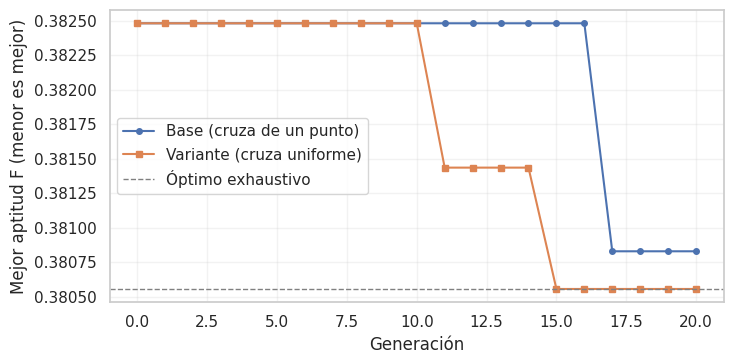

Base mejora en las generaciones: [17]
Variante mejora en las generaciones: [11, 15]


In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(range(len(res_base["history"])), res_base["history"], marker="o", ms=4, label="Base (cruza de un punto)")
ax.plot(range(len(res_variante["history"])), res_variante["history"], marker="s", ms=4, label="Variante (cruza uniforme)")
ax.axhline(evaluate(opt)["fitness"], color="gray", ls="--", lw=1, label="Óptimo exhaustivo")
ax.set(xlabel="Generación", ylabel="Mejor aptitud F (menor es mejor)")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

def generaciones_con_mejora(h):
    return [int(i) for i in range(1, len(h)) if h[i] < h[i - 1] - 1e-12]
print("Base mejora en las generaciones:", generaciones_con_mejora(res_base["history"]))
print("Variante mejora en las generaciones:", generaciones_con_mejora(res_variante["history"]))

In [ ]:
filas = []
for s in range(100):
    c = {**CONFIG_DES, "seed": s}
    fb = run_ga(**c)["metrics"]["fitness"]
    fv = run_ga_variant(**c)["metrics"]["fitness"]
    filas.append(dict(seed=s, F_base=fb, F_variante=fv))
multi = pd.DataFrame(filas)
dif = multi["F_variante"] - multi["F_base"]
F_opt = evaluate(opt)["fitness"]
resumen = pd.DataFrame({
    "Versión": ["Base", "Variante"],
    "F media": [multi["F_base"].mean(), multi["F_variante"].mean()],
    "F desv. est.": [multi["F_base"].std(), multi["F_variante"].std()],
    "F mediana": [multi["F_base"].median(), multi["F_variante"].median()],
    "Semillas en el óptimo": [int((abs(multi["F_base"] - F_opt) < 1e-12).sum()),
                               int((abs(multi["F_variante"] - F_opt) < 1e-12).sum())],
}).round(6)
print(resumen.to_string(index=False))
print("Variante mejor:", int((dif < -1e-12).sum()), "| igual:", int((dif.abs() <= 1e-12).sum()),
      "| peor:", int((dif > 1e-12).sum()))

 Versión  F media  F desv. est.  F mediana  Semillas en el óptimo
    Base 0.381560      0.001059   0.381435                     15
Variante 0.381589      0.000993   0.381874                     12
Variante mejor: 43 | igual: 16 | peor: 41


### 13.7 Interpretación de la comparación

**Qué observamos (semilla 42).** Ambas versiones parten de la misma población inicial, cuyo mejor individuo tiene $F = 0.382480$.

| Medida | Base (cruza de un punto) | Variante (cruza uniforme) |
| :--- | :--- | :--- |
| Cromosoma final $(k_1,k_2,k_3,k_4)$ | $(7,4,3,8)$ | $(8,6,4,5)$ |
| $T$ y $P$ (m³) | 1409.363 y 866.847 | 1409.984 y 866.226 |
| $F$ / $E$ (m³) | 0.380829 / 0 | 0.380556 / 0 |
| Dominios y capacidad | Genes válidos; factible ($E = 0$) | Genes válidos; factible ($E = 0$) |

Las dos asignaciones respetan los dominios y la capacidad de 1410 m³. Por eso la comparación de $P$ es legítima: se hace entre candidatos factibles, que es el único caso en que un menor $P$ significa una mejora.

**Relación con la asignación de agua.** La base trata 70 % de Aulas 1, 40 % de Biblioteca, 30 % de Cedetec y 80 % de Aulas 2. La variante trata 80 %, 60 %, 40 % y 50 %. Ambas usan casi toda la capacidad. La base deja 0.637 m³ sin usar y la variante solo 0.016 m³. Como en la rama factible $F = P/Q$, minimizar $P$ equivale a acercar $T$ a 1410 m³ sin rebasarlo. La variante lo consigue con una distribución distinta: asigna el reúso máximo a Aulas 1 y baja Aulas 2 a 50 %. La diferencia es de **0.621 m³ de agua potable**, un 0.027 % de la demanda total de marzo.

**¿Apoya la hipótesis?** En esta ejecución, sí. La variante encontró una asignación factible con menor $P$ y mejoró antes (generaciones 11 y 15) que la base (generación 17). Una enumeración exhaustiva de las 5103 combinaciones (4875 factibles) muestra que $(8,6,4,5)$ es el óptimo del modelo, mientras que la base terminó en el tercer mejor plan factible. Este es el tipo de recombinación no contigua que la cruza de un punto no podía producir a partir de ciertos padres.

**Límite de una sola semilla.** Esta evidencia es un solo caso y no demuestra que la cruza uniforme sea mejor. Cambiar el operador cambia también qué hijos produce cada número aleatorio, de modo que las dos trayectorias divergen. Con una semilla, el efecto del operador queda mezclado con la suerte del sorteo. La verificación complementaria con 100 semillas (sección 13.6, bloque «Verificación complementaria con 100 semillas») muestra que la variante gana en 43 semillas, empata en 16 y pierde en 41. Las medias de $F$ son prácticamente iguales (0.381560 contra 0.381589) y la base alcanza el óptimo en 15 semillas frente a 12 de la variante. Esto **no muestra una ventaja sistemática**. Con solo 5103 combinaciones y 400 evaluaciones, ambos operadores se acercan al óptimo, y el resultado depende más de la población inicial y del azar que del operador.

**Conclusión.** El resultado con semilla 42 es compatible con la hipótesis y relaciona el cambio de operador con un plan factible de menor consumo potable. No permite afirmar que la cruza uniforme supere en general a la de un punto. El resultado describe un modelo académico mensual (marzo de 2025) con capacidad y máximos de reúso didácticos, no una recomendación operativa de la planta.